Title: “EDA: events, calendar and uncertainty

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_csv(ROOT / "data/processed/data_daily_base.csv", parse_dates=["date"])

# 1. Weekend/holiday events: move them to the next fixing (otherwise they get lost)
EVENTS = ["is_ecb_decision_day", "is_rbi_decision_day", "is_fomc_decision_day",
          "is_us_cpi_day", "is_us_jobs_day", "is_india_budget_day"]
fix_block = df["eur_inr"].notna()[::-1].cumsum()[::-1]
df[EVENTS] = df.groupby(fix_block)[EVENTS].transform("max")

# 2. Keep only fixing days, from 8 Jan 2020
fx = df[df["eur_inr"].notna() & (df["date"] >= "2020-01-08")].reset_index(drop=True)

# 3. What we study: the daily change of EUR/INR (%) and its size
fx["chg_pct"] = fx["eur_inr"].pct_change() * 100
fx["abs_chg"] = fx["chg_pct"].abs()

# 4. Conclusions only from 2020-2024
train = fx[fx["date"] < "2025-01-01"]

print(fx.shape, train.shape)
print(fx[EVENTS].sum())

(1746, 58) (1279, 58)
is_ecb_decision_day     55
is_rbi_decision_day     42
is_fomc_decision_day    56
is_us_cpi_day           86
is_us_jobs_day          84
is_india_budget_day      8
dtype: int64


## 1. First look at my columns (2020–2024)

In [5]:
MY_COLS = ["gpr", "us_epu", "gpr_india", "in_epu", "eu_epu",
           "weekday", "day_of_month", "month", "is_de_holiday", "is_in_holiday",
           "is_payday_window", "is_diwali", "is_december", "is_india_fy_end",
           *EVENTS, "last_ecb_decision_bp", "last_rbi_decision_bp", "last_fomc_decision_bp"]

print(train[MY_COLS].describe().T[["count", "mean", "min", "max"]].round(2))
print("\nMissing values:", int(train[MY_COLS].isna().sum().sum()))
print(train[["chg_pct", "abs_chg"]].describe().round(3))

                        count    mean     min      max
gpr                    1279.0  115.34    8.32   540.83
us_epu                 1279.0  173.40   10.92  1026.38
gpr_india              1279.0    0.24    0.09     0.51
in_epu                 1279.0   89.74   23.35   193.14
eu_epu                 1279.0  280.29  141.39   479.99
weekday                1279.0    2.00    0.00     4.00
day_of_month           1279.0   15.82    1.00    31.00
month                  1279.0    6.55    1.00    12.00
is_de_holiday          1279.0    0.01    0.00     1.00
is_in_holiday          1279.0    0.05    0.00     1.00
is_payday_window       1279.0    0.14    0.00     1.00
is_diwali              1279.0    0.00    0.00     1.00
is_december            1279.0    0.08    0.00     1.00
is_india_fy_end        1279.0    0.02    0.00     1.00
is_ecb_decision_day    1279.0    0.03    0.00     1.00
is_rbi_decision_day    1279.0    0.02    0.00     1.00
is_fomc_decision_day   1279.0    0.03    0.00     1.00
is_us_cpi_

## Data quality: all 23 columns complete, values real and in plausible ranges.
## Target: a typical day moves 0.33% (≈ ₹150 per €500), with roughly as many up days as down days.
## Uncertainty: different scales, noisy daily indices (US EPU swung from 11 to 1,026 in two days), and Monday values may be low because of Sunday news. Test ## smoothing.
## Rare flags: Diwali (3), budget (6), German holidays (13). Too few to trust.
## Decision sizes: use them as categories (after a hike / cut / hold), not as averages.

## 2. Events: is EUR/INR wilder on or after event days?

Normal day (no event): 0.333 %  (1053 days)
                    days  same day  next fixing
event                                          
ECB decision          40     0.330        0.456
RBI decision          31     0.327        0.265
Fed decision          41     0.313        0.489
US inflation (CPI)    65     0.304        0.420
US jobs report        63     0.398        0.475
India budget           6     0.374        0.561


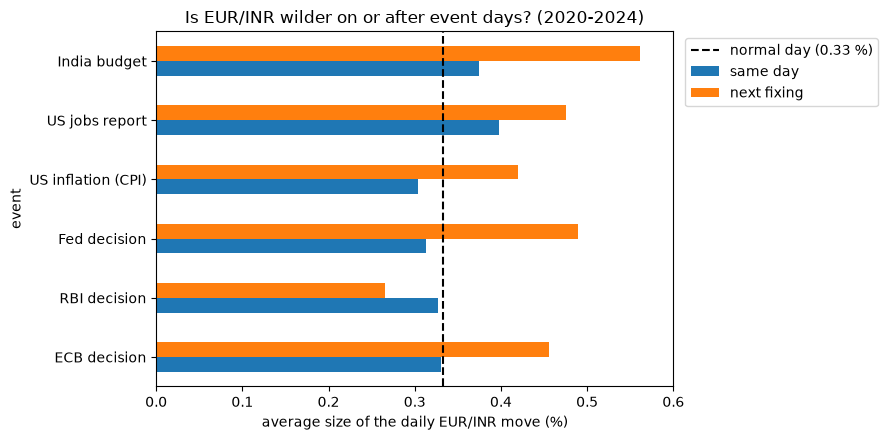

In [6]:
NAMES = {"is_ecb_decision_day": "ECB decision", "is_rbi_decision_day": "RBI decision",
         "is_fomc_decision_day": "Fed decision", "is_us_cpi_day": "US inflation (CPI)",
         "is_us_jobs_day": "US jobs report", "is_india_budget_day": "India budget"}

no_event = train[EVENTS].sum(axis=1) == 0
normal = train.loc[no_event, "abs_chg"].mean()
next_move = train["abs_chg"].shift(-1)          # the move at the NEXT fixing

rows = []
for col, name in NAMES.items():
    on_day = train[col] == 1
    rows.append({"event": name, "days": int(on_day.sum()),
                 "same day": train.loc[on_day, "abs_chg"].mean(),
                 "next fixing": next_move[on_day].mean()})
result = pd.DataFrame(rows).set_index("event").round(3)

print(f"Normal day (no event): {normal:.3f} %  ({int(no_event.sum())} days)")
print(result)

ax = result[["same day", "next fixing"]].plot(kind="barh", figsize=(9, 4.5))
ax.axvline(normal, color="black", linestyle="--", label=f"normal day ({normal:.2f} %)")
ax.set_xlim(0, 0.6)
ax.set_xlabel("average size of the daily EUR/INR move (%)")
ax.set_title("Is EUR/INR wilder on or after event days? (2020-2024)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Finding 2: EUR/INR moves more at the first fixing after big announcements (2020–2024).**
- Announcements made after the 14:10 fixing (ECB since July 2022, Fed, US CPI, US jobs) show
  normal moves on the day itself, but 30–50 % larger moves at the next fixing (0.42–0.49 % vs 0.33 %).
- RBI decisions come in the Indian morning, before the fixing: the move is normal on the day
  and calmer afterwards.
- Caveats: only 31–65 events per type (budget: 6); US jobs reports are on Fridays, so their next
  fixing is a Monday; 2020 Covid days included; this is about the size of moves, not direction.
- For features: an "event since the last fixing" flag could help predict how much the rate moves
  next, rather than its direction.

## 3. Calendar: weekday, day of month, special days

     days  move_size  direction  vs_week
Mon   251      0.356      0.091    0.022
Tue   259      0.307     -0.003    0.006
Wed   258      0.317     -0.025   -0.018
Thu   259      0.323      0.040    0.021
Fri   252      0.370     -0.055   -0.032


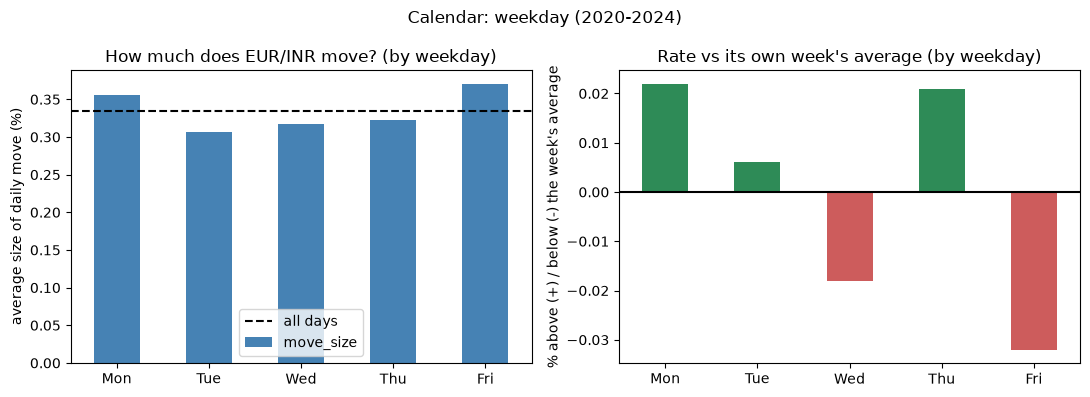

In [7]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri"]
t = train.copy()
t["week"] = t["date"].dt.to_period("W")
t["vs_week_pct"] = (t["eur_inr"] / t.groupby("week")["eur_inr"].transform("mean") - 1) * 100

by_day = t.groupby("weekday").agg(days=("abs_chg", "size"), move_size=("abs_chg", "mean"),
                                   direction=("chg_pct", "mean"), vs_week=("vs_week_pct", "mean")).round(3)
by_day.index = DAYS
print(by_day)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_day["move_size"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].axhline(t["abs_chg"].mean(), color="black", linestyle="--", label="all days")
axes[0].set_title("How much does EUR/INR move? (by weekday)")
axes[0].set_ylabel("average size of daily move (%)")
axes[0].legend()
by_day["vs_week"].plot(kind="bar", ax=axes[1],
                       color=["seagreen" if v > 0 else "indianred" for v in by_day["vs_week"]])
axes[1].axhline(0, color="black")
axes[1].set_title("Rate vs its own week's average (by weekday)")
axes[1].set_ylabel("% above (+) / below (-) the week's average")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Calendar: weekday (2020-2024)")
plt.tight_layout()
plt.show()

# day of month

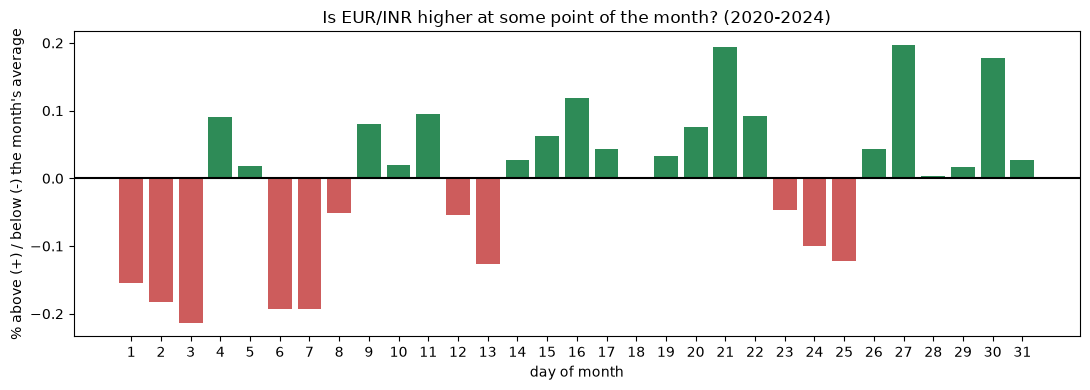

In [8]:
t["month_key"] = t["date"].dt.to_period("M")
t["vs_month_pct"] = (t["eur_inr"] / t.groupby("month_key")["eur_inr"].transform("mean") - 1) * 100
by_dom = t.groupby("day_of_month")["vs_month_pct"].mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_dom.index, by_dom.values,
       color=["seagreen" if v > 0 else "indianred" for v in by_dom.values])
ax.axhline(0, color="black")
ax.set_xticks(range(1, 32))
ax.set_xlabel("day of month")
ax.set_ylabel("% above (+) / below (-) the month's average")
ax.set_title("Is EUR/INR higher at some point of the month? (2020-2024)")
plt.tight_layout()
plt.show()

# special days

In [9]:
FLAGS = {"is_payday_window": "Payday window", "is_in_holiday": "Indian holiday",
         "is_de_holiday": "German holiday", "is_december": "December",
         "is_india_fy_end": "India FY end", "is_diwali": "Diwali"}
rows = []
for col, name in FLAGS.items():
    on = t[col] == 1
    rows.append({"group": name, "days": int(on.sum()),
                 "move_size_on": t.loc[on, "abs_chg"].mean(),
                 "move_size_other": t.loc[~on, "abs_chg"].mean(),
                 "direction_on": t.loc[on, "chg_pct"].mean()})
print(pd.DataFrame(rows).set_index("group").round(3))

                days  move_size_on  move_size_other  direction_on
group                                                            
Payday window    180         0.338            0.334         0.025
Indian holiday    61         0.319            0.335        -0.013
German holiday    13         0.254            0.335         0.012
December         105         0.282            0.339         0.044
India FY end      24         0.316            0.335         0.065
Diwali             3         0.589            0.334         0.480


**Finding 3: the calendar has almost no effect on EUR/INR (2020–2024).**
- No useful "best weekday": the difference between the highest (Mon/Thu) and lowest day (Fri)
  is about 0.05 %, roughly ₹25 per €500, far below a normal daily move (0.33 %, ≈ ₹150).
- Mondays and Fridays move a little more (weekend news; US jobs reports on Fridays).
- Day of month: the rate looks higher late in the month, but this is mainly the upward trend
  over 2020–2024 (later days are naturally higher), not a real month-end effect.
- No payday effect. December is about 15 % calmer than other months (holiday season).
- Diwali (3 days) and German holidays (13 days) are too rare to judge.
- Shortlist: keep `weekday` and `is_december` (move size); drop or treat with care
  `is_diwali`, `is_payday_window`, `is_in_holiday`, `is_de_holiday`, `is_india_fy_end`.